# Telco Customer Churn

## The dataset

`telco_churn.csv` is IBM's sample telecom dataset. Each row is one customer of a fictional phone and internet company, and the columns describe who they are, which services they bought, how they are billed, and whether they left.

**7043 rows, 21 columns.** The target is `Churn`, so this is a binary classification problem. 26.5% of customers churned, which makes the classes imbalanced at roughly 2.8 to 1.

`customerID` is a unique identifier with 7043 distinct values and carries no information about behaviour, so it is dropped. That leaves 19 usable features.

## The features

**Who the customer is**

| Feature | Values | Meaning |
|---|---|---|
| `gender` | Female, Male | |
| `SeniorCitizen` | 0, 1 | 1 if the customer is a senior citizen (16.2% of rows). Stored as an integer but it is categorical |
| `Partner` | Yes, No | Whether the customer has a partner |
| `Dependents` | Yes, No | Whether the customer has dependents, such as children |

**Phone services**

| Feature | Values | Meaning |
|---|---|---|
| `PhoneService` | Yes, No | Whether the customer has a phone line |
| `MultipleLines` | Yes, No, No phone service | Whether they have more than one line. The third level only occurs when `PhoneService` is No |

**Internet services**

| Feature | Values | Meaning |
|---|---|---|
| `InternetService` | DSL, Fiber optic, No | Which internet product they bought |
| `OnlineSecurity` | Yes, No, No internet service | Security add-on |
| `OnlineBackup` | Yes, No, No internet service | Backup add-on |
| `DeviceProtection` | Yes, No, No internet service | Device protection add-on |
| `TechSupport` | Yes, No, No internet service | Technical support add-on |
| `StreamingTV` | Yes, No, No internet service | TV streaming |
| `StreamingMovies` | Yes, No, No internet service | Movie streaming |

The six add-on columns all use `No internet service` for exactly the same 1526 customers, which are the ones with `InternetService = No`.

**Account and billing**

| Feature | Values | Meaning |
|---|---|---|
| `tenure` | 0 to 72 | Months the customer has been with the company |
| `Contract` | Month-to-month, One year, Two year | Contract length. This one has a natural order |
| `PaperlessBilling` | Yes, No | |
| `PaymentMethod` | Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic) | How they pay. No natural order |
| `MonthlyCharges` | 18.25 to 118.75 | Amount billed per month |
| `TotalCharges` | 18.80 to 8684.80 | Total billed so far. Stored as text in the raw file |

**Target**

| Feature | Values | Meaning |
|---|---|---|
| `Churn` | Yes, No | Whether the customer left. Converted to 1/0 with Yes = 1 |


## 1. Exploratory Data Analysis

In [263]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import TargetEncoder, StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [264]:
dataset = pd.read_csv("telco_churn.csv")
dataset.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [265]:
dataset.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [266]:
#Converting churn to 1/0
#Yes = 1 so that recall answeres "What fraction of churners did i catch?"
dataset['Churn'] = (dataset['Churn'] == 'Yes').astype(int)

In [267]:
#Dropping customerID
dataset = dataset.drop('customerID', axis=1)
dataset.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


### Missing values

`isna()` returns 0 which is misleading. `TotalCharges` is stored as text and 11 rows contain a blank space instead of a number, so pandas counts them as present. Converting with `errors='coerce'` turns those blanks into real NaN, and then the 11 show up.


In [268]:
dataset.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [269]:
dataset['TotalCharges'] = pd.to_numeric(dataset['TotalCharges'], errors='coerce')

In [270]:
dataset.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [271]:
#Showing how many nan values there are in TotalCharges
dataset['TotalCharges'].isna().sum()


np.int64(11)

### Numeric features

There are only three real numeric columns: `tenure`, `MonthlyCharges` and `TotalCharges`. `SeniorCitizen` and `Churn` also show up in `describe()` but both are categorical, they are just stored as integers.

`MonthlyCharges` has a big spike at around $20, which is around 1400 customers. I check below whether this group is the customers with no `InternetService`, since that would explain the low charge.

Note that the spike means the distribution is bimodal rather than skewed. A skew number cannot describe a distribution with two peaks, so it reports close to zero here even though the shape is clearly not symmetric. `tenure` has the same problem, it is high at both ends and low in the middle.

In [272]:
dataset.describe()


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000
mean,0.162147,32.371149,64.761692,2283.300441,0.265370
std,0.368612,24.559481,30.090047,2266.771362,0.441561
min,0.000000,0.000000,18.250000,18.800000,0.000000
25%,0.000000,9.000000,35.500000,401.450000,0.000000
50%,0.000000,29.000000,70.350000,1397.475000,0.000000
75%,0.000000,55.000000,89.850000,3794.737500,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


/var/folders/hj/5yhwvl350_sc9jstlf12pw9m0000gn/T/ipykernel_46720/2494643125.py:3: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  dataset.hist(ax=ax)


array([[<Axes: title={'center': 'SeniorCitizen'}>,
        <Axes: title={'center': 'tenure'}>],
       [<Axes: title={'center': 'MonthlyCharges'}>,
        <Axes: title={'center': 'TotalCharges'}>],
       [<Axes: title={'center': 'Churn'}>, <Axes: >]], dtype=object)

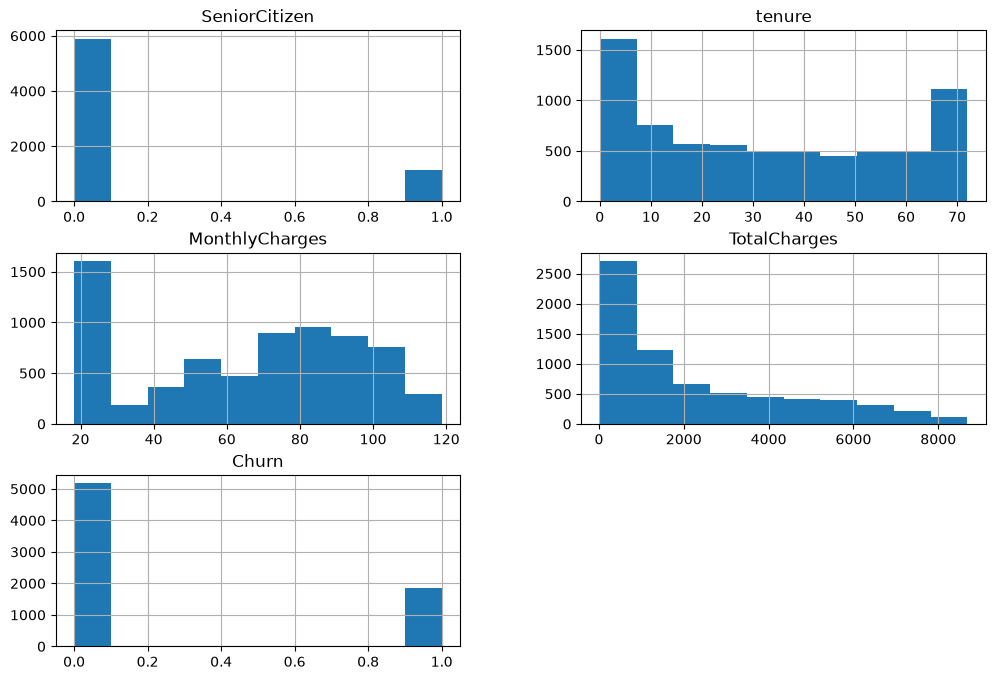

In [273]:
fig, ax = plt.subplots(1, 1, figsize=(12,8))

dataset.hist(ax=ax)

In [274]:
dataset.groupby('InternetService')['MonthlyCharges'].describe()



,count,mean,std,min,25%,50%,75%,max
InternetService,,,,,,,,
DSL,2421.0,58.102169,16.259522,23.45,46.20,56.150,69.90,94.80
Fiber optic,3096.0,91.500129,12.663039,67.75,80.55,91.675,101.15,118.75
No,1526.0,21.079194,2.164221,18.25,19.70,20.150,20.90,26.90


The table confirms the price bands are almost separate:

| InternetService | range | count |
|---|---|---|
| No | $18.25 to $26.90 | 1526 |
| DSL | $23.45 to $94.80 | 2421 |
| Fiber optic | $67.75 to $118.75 | 3096 |

A `MonthlyCharges` below $27 means no internet almost without exception. So this column is partly an encoding of which product the customer bought, not only what they pay.

### Churn by internet service

Next I look at who churns, split by `InternetService`. Fiber optic customers churn the most at 42%, and they are also the ones paying the most at $91 on average. The overall churn rate is 26.5%.

That is a problem for interpretation. If a model says high `MonthlyCharges` predicts churn, I cannot tell whether price drives churn or whether fiber optic does and price just follows along. Both give identical predictions but mean different things. One says lower the price, the other says fix the fiber service.

In [275]:
dataset.groupby('InternetService')['Churn'].mean()


InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn, dtype: float64

### Untangling it by stratifying

Stratifying means looking at the relationship inside each service type, so service type is held constant. If churn still rises with price inside the fiber group and inside the DSL group, then price matters on its own. If it does not, then service type is the whole story and price was only a proxy.

The result reverses. Inside DSL, churn falls from 36% to 2% as price rises. Inside fiber optic it falls from 59% to 34%. So within a service type, paying more goes with churning less, which is the opposite of the aggregate.

This is Simpson's Paradox, where a relationship in the aggregate reverses inside every subgroup.

I would not say that price causes loyalty. Inside a service type a higher bill mostly means the customer bought more add-on services and signed a longer contract, and those are what go with lower churn. The useful conclusion is that the raw reading of "expensive customers churn" is wrong, and service type was doing the work.

One caution on the table: the DSL $89.85 to $118.75 cell only has 50 customers, so its 2% rate rests on very few people.

In [276]:
dataset.groupby(['InternetService', pd.qcut(dataset.MonthlyCharges, 4)])['Churn'].agg(['size', 'mean'])

size      mean
InternetService MonthlyCharges                 
DSL             (18.249, 35.5]    236  0.360169
                (35.5, 70.35]    1605  0.211215
                (70.35, 89.85]    530  0.064151
                (89.85, 118.75]    50  0.020000
Fiber optic     (35.5, 70.35]     161  0.590062
                (70.35, 89.85]   1227  0.509372
                (89.85, 118.75]  1708  0.337822
No              (18.249, 35.5]   1526  0.074050

<Axes: title={'center': 'tenure'}, xlabel='Churn'>

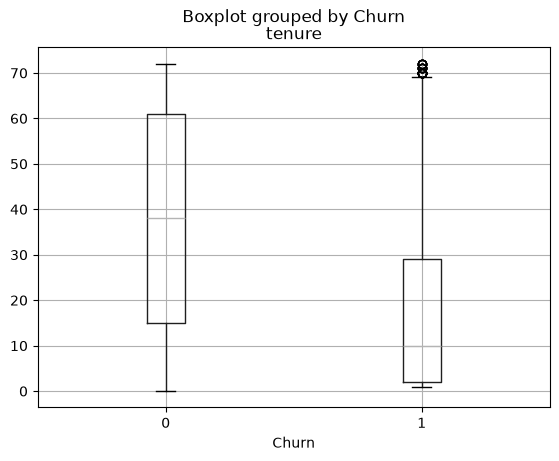

In [277]:
dataset.boxplot(column='tenure', by='Churn')


`tenure` separates the two classes clearly. Customers who churn have much shorter tenure, which fits the U-shape in the histogram: a lot of recent signups and a lot of long-term survivors.

`tenure`, `Contract`, `MonthlyCharges` and the number of add-on services all move together, so they should be read as one cluster rather than four independent signals. That matters when I look at feature importances later.

In [278]:
dataset.mode()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.05,20.2,0


In [279]:
dataset.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


### Correlation analysis on numeric columns


In [280]:
correlation = dataset.corr(numeric_only=True)
correlation.style.background_gradient(cmap='coolwarm')

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
SeniorCitizen,1.000000,0.016567,0.220173,0.102411,0.150889
tenure,0.016567,1.000000,0.247900,0.825880,-0.352229
MonthlyCharges,0.220173,0.247900,1.000000,0.651065,0.193356
TotalCharges,0.102411,0.825880,0.651065,1.000000,-0.199484
Churn,0.150889,-0.352229,0.193356,-0.199484,1.000000


# Processing

### Missing values in `TotalCharges`
Every one of them has `tenure = 0`, and `tenure = 0` does not happen anywhere else. So the value is missing if and only if the customer has been subscribed for zero months. These customers have never been billed, so there is no total to record.

That is why I fill with 0 rather than dropping the rows or using the median. The median would insert about 2283 for a customer who has paid nothing. Dropping would remove real customers who have just signed up.

I keep dropping and median imputation as alternatives to compare in the hyperparameter search later.

In [281]:
#Filling na with 0 as explained in the EDA section
dataset['TotalCharges'] = dataset['TotalCharges'].fillna(0)


### Encoding